# 🫀 Heart Disease Prediction: EDA, Feature Engineering & Stacking

First Lets Import necessary libraries:

In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold

from sklearn.ensemble import StackingClassifier

import xgboost as xgb
import lightgbm as lgb
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import log_loss,classification_report, roc_auc_score, ConfusionMatrixDisplay, confusion_matrix


from sklearn.linear_model import Ridge

import warnings
warnings.filterwarnings("ignore")
np.random.seed(42)

This dataset has 302 rows and 14 columns(features).

The dataset provided has the following columns of multiple-choice data:

- age : Age of the patient

- sex : Sex of the patient

- exang: exercise induced angina (1 = yes; 0 = no)

- ca: number of major vessels (0-3)

- cp : Chest Pain type chest pain type:
  * Value 1: typical angina
  * Value 2: atypical angina
  * Value 3: non-anginal pain
  * Value 4: asymptomatic

- trtbps : resting blood pressure (in mm Hg)

- chol : cholestoral in mg/dl fetched via BMI sensor

- fbs : (fasting blood sugar > 120 mg/dl) (1 = true; 0 = false)

- rest_ecg : resting electrocardiographic results

  * Value 0: normal
  * Value 1: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV)
  * Value 2: showing probable or definite left ventricular hypertrophy by Estes' criteria
- thalach : maximum heart rate achieved

- thall : Thalium Stress Test result ~ (0,3)

- oldpeak : Previous peak

- slp : Slope

- target : 0= less chance of heart attack 1= more chance of heart attack

In [5]:
train_df = pd.read_csv(r"/kaggle/input/competitions/playground-series-s6e2/train.csv", index_col = 'id')
test_df = pd.read_csv(r"/kaggle/input/competitions/playground-series-s6e2/test.csv", index_col = 'id')
sample_submission = pd.read_csv(r"/kaggle/input/competitions/playground-series-s6e2/sample_submission.csv", index_col = 'id')

print("train data :", train_df.shape)
print("test data :", test_df.shape)
print("sample_submission_data :", sample_submission.shape)

train data : (630000, 14)
test data : (270000, 13)
sample_submission_data : (270000, 1)


In [6]:
train_df.head()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
id,,,,,,,,,,,,,,
0,58,1,4,152,239,0,0,158,1,3.6,2,2,7,Presence
1,52,1,1,125,325,0,2,171,0,0.0,1,0,3,Absence
2,56,0,2,160,188,0,2,151,0,0.0,1,0,3,Absence
3,44,0,3,134,229,0,2,150,0,1.0,2,0,3,Absence
4,58,1,4,140,234,0,2,125,1,3.8,2,3,3,Presence


In [7]:
test_df.columns

Index(['Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120',
       'EKG results', 'Max HR', 'Exercise angina', 'ST depression',
       'Slope of ST', 'Number of vessels fluro', 'Thallium'],
      dtype='object')

In [8]:
print(train_df.columns)

Index(['Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120',
       'EKG results', 'Max HR', 'Exercise angina', 'ST depression',
       'Slope of ST', 'Number of vessels fluro', 'Thallium', 'Heart Disease'],
      dtype='object')


In [8]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 630000 entries, 0 to 629999
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Age                      630000 non-null  int64  
 1   Sex                      630000 non-null  int64  
 2   Chest pain type          630000 non-null  int64  
 3   BP                       630000 non-null  int64  
 4   Cholesterol              630000 non-null  int64  
 5   FBS over 120             630000 non-null  int64  
 6   EKG results              630000 non-null  int64  
 7   Max HR                   630000 non-null  int64  
 8   Exercise angina          630000 non-null  int64  
 9   ST depression            630000 non-null  float64
 10  Slope of ST              630000 non-null  int64  
 11  Number of vessels fluro  630000 non-null  int64  
 12  Thallium                 630000 non-null  int64  
 13  Heart Disease            630000 non-null  object 
dtypes: float6

In [9]:
train_df.isnull().sum()

Age                        0
Sex                        0
Chest pain type            0
BP                         0
Cholesterol                0
FBS over 120               0
EKG results                0
Max HR                     0
Exercise angina            0
ST depression              0
Slope of ST                0
Number of vessels fluro    0
Thallium                   0
Heart Disease              0
dtype: int64

Checking for missing values shows that all features in the training dataset have zero null entries. This means the dataset is complete and we can proceed without needing any imputation or additional preprocessing for missing data.

In [11]:
print(train_df.duplicated().sum())

0


No duplicate rows are present in the dataset.

In [12]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,630000.0,54.136706,8.256301,29.0,48.0,54.0,60.0,77.0
Sex,630000.0,0.714735,0.451541,0.0,0.0,1.0,1.0,1.0
Chest pain type,630000.0,3.312752,0.851615,1.0,3.0,4.0,4.0,4.0
BP,630000.0,130.497433,14.975802,94.0,120.0,130.0,140.0,200.0
Cholesterol,630000.0,245.011814,33.681581,126.0,223.0,243.0,269.0,564.0
FBS over 120,630000.0,0.079987,0.271274,0.0,0.0,0.0,0.0,1.0
EKG results,630000.0,0.981660,0.998783,0.0,0.0,0.0,2.0,2.0
Max HR,630000.0,152.816763,19.112927,71.0,142.0,157.0,166.0,202.0
Exercise angina,630000.0,0.273725,0.445870,0.0,0.0,0.0,1.0,1.0
ST depression,630000.0,0.716028,0.948472,0.0,0.0,0.1,1.4,6.2


In [23]:
train_df['ST depression'].value_counts()

ST depression
0.00    314939
1.20     29269
1.00     28647
1.60     28395
1.40     27146
         ...  
4.70         4
5.10         2
2.12         1
5.90         1
0.06         1
Name: count, Length: 66, dtype: int64

In [24]:
train_df['Cholesterol'].value_counts()

Cholesterol
234    29562
269    24604
254    21887
226    17562
243    17405
       ...  
165        1
138        1
173        1
130        1
202        1
Name: count, Length: 150, dtype: int64

In [58]:
train_df['EKG results'].value_counts()

EKG results
0    320116
2    308562
1      1322
Name: count, dtype: int64

In [62]:
train_df['Slope of ST'].value_counts()

Slope of ST
1    358293
2    256215
3     15492
Name: count, dtype: int64

In [67]:
train_df['Number of vessels fluro'].value_counts()

Number of vessels fluro
0    445862
1    106978
2     54303
3     22857
Name: count, dtype: int64

In [65]:
train_df['Thallium'].value_counts()

Thallium
3    372286
7    246748
6     10966
Name: count, dtype: int64

## Data Visualization

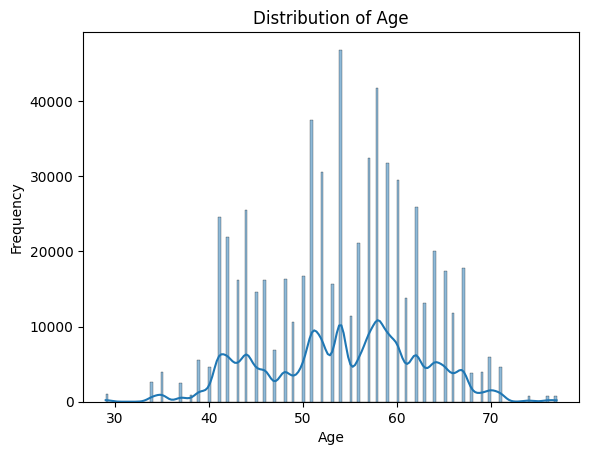

In [5]:
sns.histplot(data= train_df, x='Age', kde=True)

#, palette='Set1')
plt.title('Distribution of Age')
plt.ylabel("Frequency")
plt.xlabel("Age")

plt.show()

plt.show()

### Age Distribution

This histogram (with a Kernel Density Estimate curve) visualizes the distribution of patient ages. 

* **Observation:** The age distribution is approximately bell-shaped, peaking between 50 and 60 years old.
* **Insight:** Most patients in this dataset are middle-aged to older adults, which aligns with typical heart disease risk demographics.

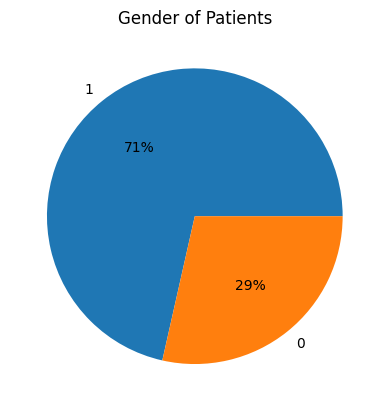

In [7]:
data = train_df['Sex'].value_counts()
plt.pie(data, labels=data.index, autopct='%.0f%%')
plt.title("Gender of Patients")

plt.show()

### Gender Distribution

This pie chart illustrates the proportion of male and female patients in the dataset based on the 'Sex' feature.

* **Observation:** The dataset is predominantly composed of class '1' (71%), while class '0' makes up the remaining 29%. 
* **Insight:** Assuming standard dataset encoding (1 = Male, 0 = Female), there is a clear gender imbalance. This male-dominated distribution is common in historical heart disease datasets and should be kept in mind during model evaluation (e.g., using stratified splits).

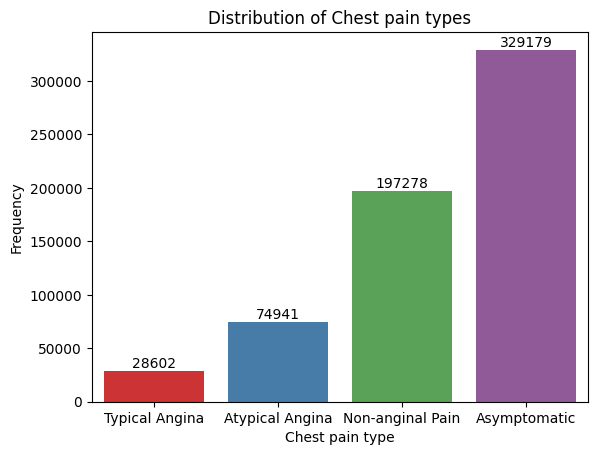

In [3]:
cp_labels = {
    1: 'Typical Angina',
    2: 'Atypical Angina',
    3: 'Non-anginal Pain',
    4: 'Asymptomatic'
}

chart = sns.countplot(x=train_df['Chest pain type'], palette='Set1')

plt.title('Distribution of Chest pain types')
plt.ylabel("Frequency")
plt.xlabel("Chest pain type")

plt.xticks(ticks=[0, 1, 2, 3], labels=list(cp_labels.values()))

for container in chart.containers:
    chart.bar_label(container)

plt.show()

### Chest Pain Type Distribution

This bar chart displays the frequency of each chest pain category in the dataset.

* **Observation:** The feature is highly imbalanced. **Asymptomatic** is the most dominant category with 329,179 cases, followed by **Non-anginal Pain** (197,278). **Atypical Angina** accounts for 74,941 cases, while **Typical Angina** is the least frequent category with 28,602 cases.
* **Insight:** Because of this significant class imbalance, model evaluation should rely on robust metrics (like F1-score or ROC-AUC) rather than simple accuracy. Additionally, this categorical feature will likely require encoding (e.g., One-Hot Encoding) depending on the chosen model.

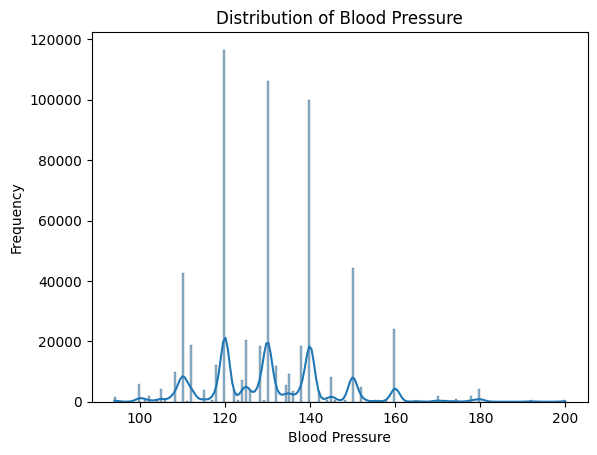

In [15]:
sns.histplot(data= train_df, x='BP', kde=True)

#, palette='Set1')
plt.title('Distribution of Blood Pressure')
plt.ylabel("Frequency")
plt.xlabel("Blood Pressure")

plt.show()

### Blood Pressure Distribution

This histogram (with a Kernel Density Estimate curve) visualizes the distribution of patients' blood pressure (BP).

* **Observation:** The distribution is highly multi-modal with sharp, distinct spikes at regular intervals (e.g., 120, 130, 140, 150). The values range roughly from 90 to 200. 
* **Insight:** The presence of these sharp peaks strongly suggests that blood pressure readings were rounded to the nearest 10 by the data recorders, making this continuous variable appear somewhat discrete. The KDE curve shows the highest concentration around 120–130 mmHg.
* **Modeling Note:** Tree-based models (like XGBoost or Random Forest) will naturally handle these discrete groupings well. Alternatively, feature engineering (such as binning BP into clinical categories: Normal, Elevated, High) could yield better linear model performance.

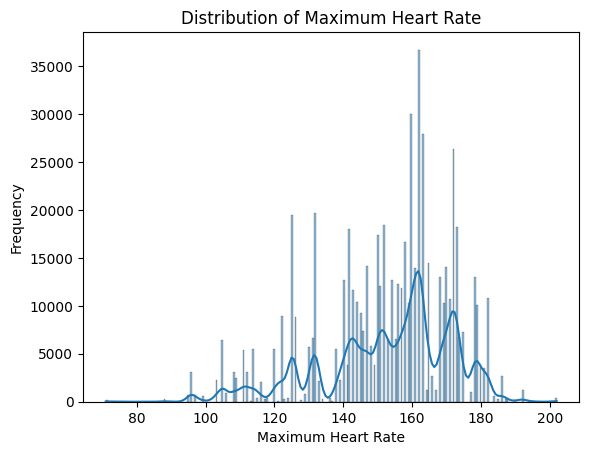

In [17]:
sns.histplot(data= train_df, x='Max HR', kde=True)

#, palette='Set1')
plt.title('Distribution of Maximum Heart Rate')
plt.ylabel("Frequency")
plt.xlabel("Maximum Heart Rate")

plt.show()

### Maximum Heart Rate Distribution

This histogram (with a Kernel Density Estimate curve) visualizes the distribution of the maximum heart rate achieved by patients (Max HR).

* **Observation:** The distribution is roughly bell-shaped and slightly right-skewed, with a prominent peak around 160 bpm. Similar to the blood pressure feature, there are sharp, discrete spikes throughout the range.
* **Insight:** Most patients achieve a maximum heart rate between 140 and 170 bpm, which is physiologically typical for cardiac stress tests. The long right tail indicates a few individuals reached exceptionally high heart rates (up to ~200 bpm), while lower values (below 100) are relatively rare. 
* **Modeling Note:** The presence of sharp spikes again suggests that values were recorded as discrete integers. This feature typically has strong predictive power in heart disease classification. Standard scaling may be beneficial if using distance-based or linear models.

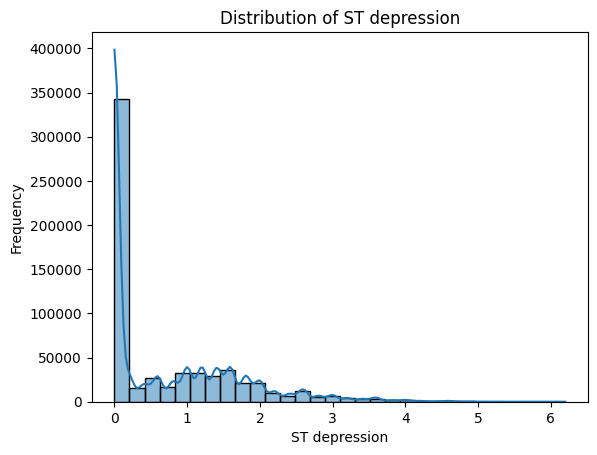

In [44]:
sns.histplot(data= train_df, x='ST depression', kde=True, bins = 30)

plt.title('Distribution of ST depression')
plt.ylabel("Frequency")
plt.xlabel("ST depression")

plt.show()

### ST Depression Distribution

This histogram (with a Kernel Density Estimate curve) visualizes the distribution of ST depression induced by exercise relative to rest.

* **Observation:** The distribution is extremely right-skewed (positively skewed) and zero-inflated. A massive proportion of patients have an ST depression value of exactly 0, causing a huge spike at the beginning. The distribution then drops sharply and forms a long tail extending towards higher values (up to ~6.5).
* **Insight:** Clinically, an ST depression value greater than 0 is often a strong indicator of ischemia (reduced blood flow to the heart). The zero-inflated nature suggests that many patients in this dataset do not exhibit this specific symptom.
* **Modeling Note:** Due to the severe skewness, linear models may struggle. Tree-based models (like XGBoost or Random Forest) can handle this non-linear distribution naturally. For linear models, a log transformation (e.g., `np.log1p`) or creating a binary flag (ST depression > 0) might be beneficial.

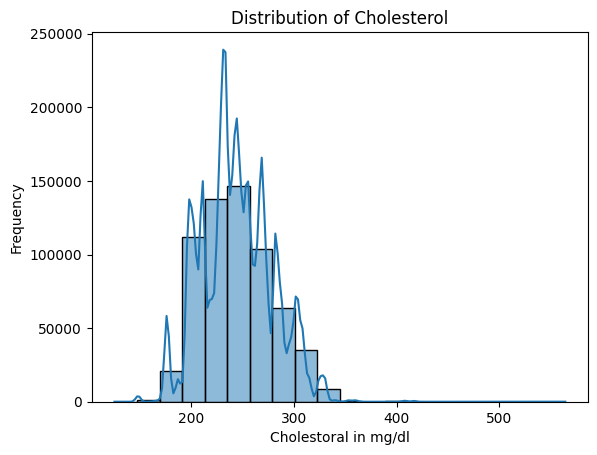

In [38]:
sns.histplot(data= train_df, x='Cholesterol', kde=True, bins = 20)

plt.title('Distribution of Cholesterol')
plt.ylabel("Frequency")
plt.xlabel("Cholestoral in mg/dl")

plt.show()

### Cholesterol Distribution

This histogram (with a Kernel Density Estimate curve) visualizes the distribution of serum cholesterol levels (mg/dl).

* **Observation:** The distribution is roughly bell-shaped, centered around 240 mg/dl, with a slight right skew. Most patients fall within the 150–350 mg/dl range. However, the KDE curve reveals multiple distinct peaks (multi-modality), and there is a long, sparse tail extending beyond 400 mg/dl indicating a few extreme outliers.
* **Insight:** The multiple peaks suggest that cholesterol values may have been recorded in discrete intervals or rounded. Clinically, higher cholesterol levels (especially > 240 mg/dl) are a known risk factor for heart disease.
* **Modeling Note:** Due to the slight right skew and the presence of extreme outliers, using a robust scaler (e.g., `RobustScaler`) or applying a log transformation might help linear models. Tree-based algorithms, however, are generally robust to this distribution.

### Handling Outliers: Winsorization (Clipping)

Following the EDA, we observed a long right tail with extreme outliers in the `Cholesterol` feature. To mitigate the impact of these extreme values without losing valuable data points, we applied a clipping technique (Winsorization) at the 1st and 99th percentiles.

* **Implementation:** 
  * Values below the 1st percentile (`lo`) are replaced with `lo`.
  * Values above the 99th percentile (`hi`) are replaced with `hi`.
  * A new column (`Cholesterol2`) is created to preserve the original raw data.
* **Rationale:** Extreme outliers can disproportionately influence model weights and decision boundaries (especially in distance-based or linear models). By capping the extreme values at the 1st and 99th percentiles, we retain 98% of the original data distribution while preventing a few extreme cases from skewing the model's learning process.

In [10]:
lo = train_df['Cholesterol'].quantile(0.01)
hi = train_df['Cholesterol'].quantile(0.99)
train_df['Cholesterol2'] = train_df['Cholesterol'].clip(lo, hi)

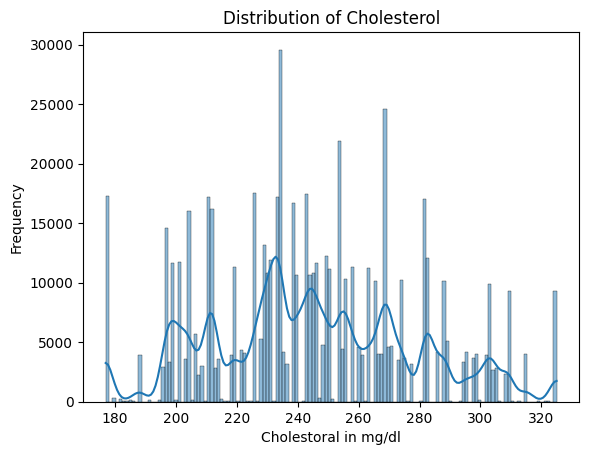

In [11]:
sns.histplot(data= train_df, x='Cholesterol2', kde=True)

plt.title('Distribution of Cholesterol')
plt.ylabel("Frequency")
plt.xlabel("Cholestoral in mg/dl")

plt.show()

### Cholesterol Distribution (After Winsorization)

This histogram displays the distribution of the newly created `Cholesterol2` feature after clipping extreme values at the 1st and 99th percentiles.

* **Observation:** The long tails and extreme outliers present in the original data have been successfully removed. The data range is now tightly bounded between approximately 175 and 325 mg/dl. The multimodal (multi-peaked) nature of the distribution remains visible, reflecting the inherent discreteness of the recorded measurements.
* **Impact:** By capping these extreme outliers without discarding any data rows, we have reduced the variance and prevented extreme values from disproportionately skewing the model's learning process. This cleaner distribution will help distance-based and linear algorithms converge better, while still preserving the core patterns of the dataset.

In [9]:
lo = train_df['BP'].quantile(0.01)
hi = train_df['BP'].quantile(0.99)
train_df['BP2'] = train_df['BP'].clip(lo, hi)

### Handling Outliers in Blood Pressure (Winsorization)

Similar to the `Cholesterol` feature, the exploratory data analysis for Blood Pressure (`BP`) revealed a sparse tail of extreme values. To stabilize the distribution and prevent these rare, high values from disproportionately influencing the model, we applied the same clipping technique (Winsorization) at the 1st and 99th percentiles.

* **Implementation:** The `BP` values are capped between the 1st (`lo`) and 99th (`hi`) percentiles, and saved into a new column `BP2` to preserve the original data.
* **Rationale:** Clinically, extreme blood pressure readings are critical, but in a machine learning context, a few extreme outliers can skew the decision boundaries of linear models. Capping the values ensures a more robust training process while retaining 98% of the data's natural distribution and maintaining consistency in our preprocessing pipeline.

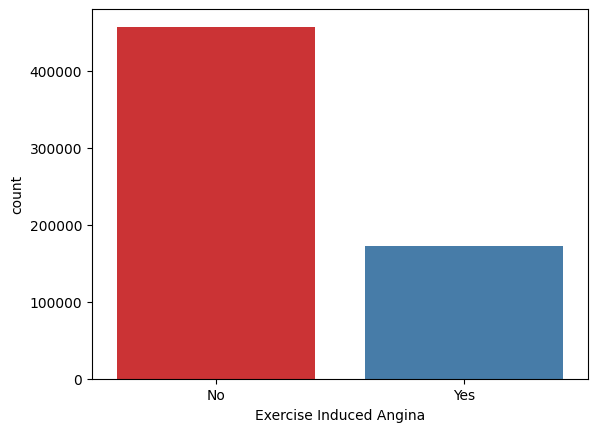

In [54]:
chart = sns.countplot(data=train_df, x="Exercise angina", palette='Set1')
plt.xlabel("Exercise Induced Angina")
chart.set_xticklabels(['No', 'Yes'])

plt.show()

### Exercise Induced Angina Distribution

This bar chart visualizes the distribution of patients who experienced exercise-induced angina.

* **Observation:** The dataset is noticeably imbalanced regarding this feature. The majority of patients fall into the **"No"** category (approximately 460,000 cases), indicating they did not experience angina during exercise. A smaller subset is in the **"Yes"** category (approximately 170,000 cases). 
* **Insight:** Clinically, exercise-induced angina is a strong indicator of coronary artery disease. Given the class imbalance, tree-based models (like the ones used in this notebook) are generally robust to this. However, evaluating the model using metrics like Precision, Recall, or F1-score will provide a more accurate picture than simple accuracy.
* **Implementation Note:** The raw dataset typically uses binary encoding (0 and 1) for this feature. For better visualization and interpretability, the x-axis labels were explicitly mapped to "No" and "Yes".

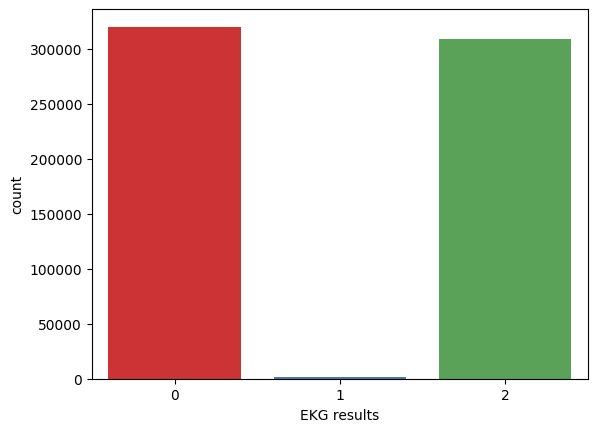

In [61]:
chart = sns.countplot(data=train_df, x="EKG results", palette='Set1')
plt.xlabel("EKG results")

plt.show()

### EKG Results Distribution

This bar chart displays the frequency of different Electrocardiogram (EKG) results in the dataset.

* **Observation:** The distribution is highly skewed. Categories **0** and **2** are the dominant classes, with roughly similar frequencies (approximately 320,000 and 310,000 cases, respectively). Conversely, Category **1** is exceptionally rare, appearing as a nearly invisible bar on the chart.
* **Insight:** In clinical terms, these categories typically represent: 0 = Normal, 1 = ST-T wave abnormality, and 2 = Left ventricular hypertrophy. The extreme rarity of class 1 suggests that this specific abnormality is very uncommon in this patient cohort.
* **Modeling Note:** Because class 1 has so few samples, models might struggle to learn its patterns and could tend to ignore it. Given that we are using tree-based models (which handle imbalance reasonably well), we can proceed, but it is important to monitor metrics like the macro F1-score to ensure the model isn't completely neglecting this rare class.

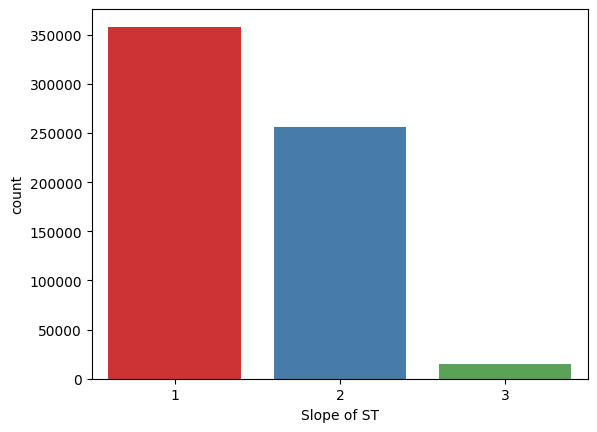

In [63]:
chart = sns.countplot(data=train_df, x="Slope of ST", palette='Set1')
plt.xlabel("Slope of ST")

plt.show()

### Slope of ST Distribution

This bar chart visualizes the distribution of the ST segment slope, which is a key ECG measurement indicating how the heart's electrical signal returns to baseline after a beat.

* **Observation:** The feature is highly imbalanced. Category **1** is the most dominant (~360,000 cases), followed by Category **2** (~260,000 cases). Category **3** is extremely rare, accounting for only a tiny fraction of the dataset (~15,000 cases).
* **Insight:** In standard clinical datasets, these categories typically represent: 1 = Upsloping, 2 = Flat, and 3 = Downsloping. A downsloping or flat ST segment is often clinically associated with a higher risk of coronary artery disease. However, the severe rarity of Category 3 means the model has very few examples to learn from. 
* **Modeling Note:** While the tree-based models used in this notebook (XGBoost, LightGBM, etc.) are generally robust to class imbalance, we should rely on metrics like Macro F1-score or ROC-AUC to ensure the model doesn't completely ignore the rare Category 3.

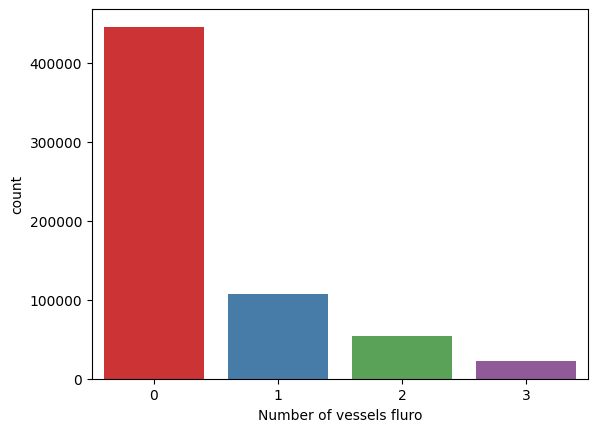

In [64]:
chart = sns.countplot(data=train_df, x="Number of vessels fluro", palette='Set1')
plt.xlabel("Number of vessels fluro")

plt.show()

### Number of Vessels (Fluoroscopy) Distribution

This bar chart displays the distribution of the number of major vessels (0 to 3) colored by fluoroscopy.

* **Observation:** The distribution follows a clear right-skewed pattern, decreasing monotonically. Category **0** is by far the most dominant class (over 440,000 cases), while the frequency drops significantly for categories 1, 2, and finally 3 (which has the fewest cases, around 20,000).
* **Insight:** Clinically, this feature indicates the number of major blood vessels with significant blockages. A value of 0 suggests no visible blockage via fluoroscopy, while a higher number (up to 3) indicates more severe coronary artery disease.
* **Modeling Note:** This is another highly imbalanced categorical feature. Since the dataset is heavily skewed toward class 0, we must ensure our model does not become biased toward predicting the majority class. Tree-based models (Random Forest, XGBoost, etc.) are generally robust to this, but using stratified cross-validation is highly recommended to maintain the class ratio across folds.

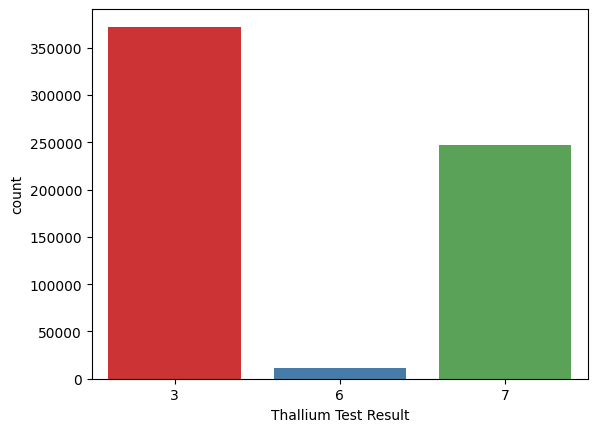

In [66]:
chart = sns.countplot(data=train_df, x="Thallium", palette='Set1')
plt.xlabel("Thallium Test Result")

plt.show()

### Thallium Test Results Distribution

This bar chart visualizes the distribution of the Thallium stress test results, which are used to evaluate blood flow to the heart muscle.

* **Observation:** The feature is highly imbalanced. Category **3** is the dominant class (over 370,000 cases), followed by Category **7** (~250,000 cases). Category **6** is exceptionally rare, appearing as a very small fraction of the dataset.
* **Insight:** In standard clinical datasets, these categories typically represent: 
  * **3** = Normal blood flow
  * **6** = Fixed Defect (scar tissue from a previous heart attack)
  * **7** = Reversible Defect (ischemia/reduced blood flow during stress)
  The extreme rarity of Category 6 suggests that patients with fixed defects are very uncommon in this specific cohort.
* **Modeling Note:** Given the severe class imbalance, particularly for Category 6, the model might struggle to learn its specific patterns. While tree-based models handle imbalance better than linear ones, using evaluation metrics like the Macro F1-score will be crucial to ensure the minority class is not completely ignored.

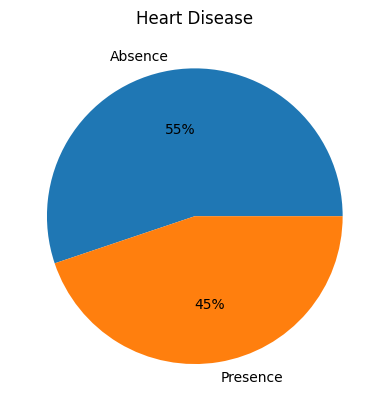

In [72]:
data = train_df['Heart Disease'].value_counts()
plt.pie(data, labels=data.index, autopct='%.0f%%')
plt.title("Heart Disease")

plt.show()

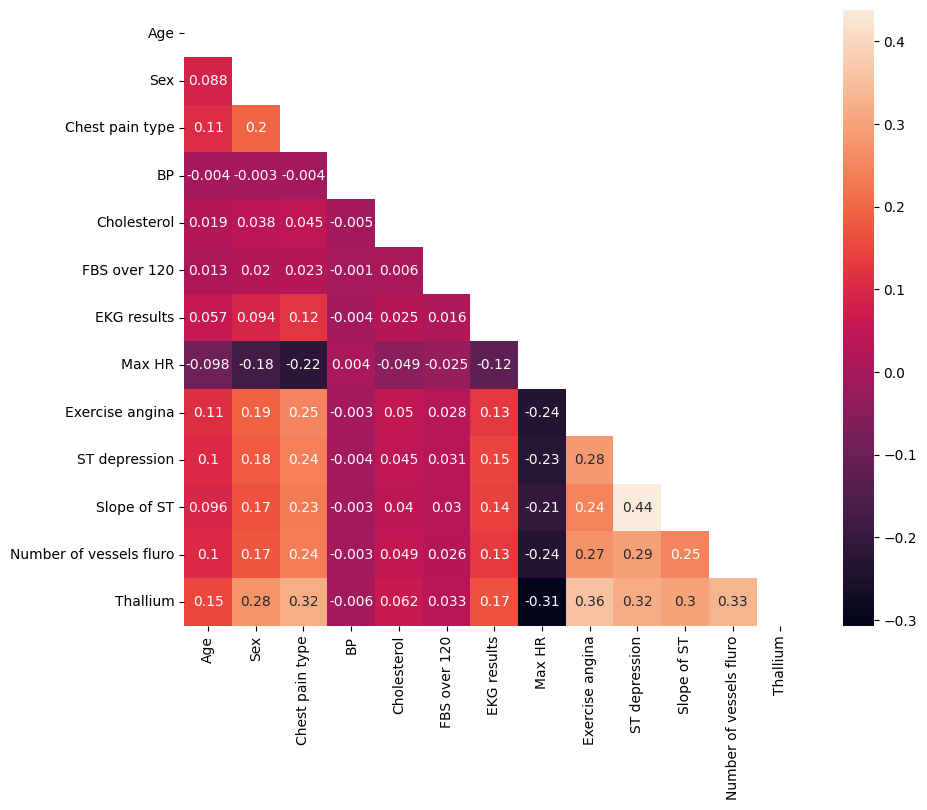

In [71]:
plt.figure(figsize=(10, 8))

numeric_df = train_df[train_df.describe().columns]

matrix = np.triu(numeric_df.corr())
sns.heatmap(numeric_df.corr().round(3), mask=matrix, annot=True)

plt.show()

### Correlation Matrix

This heatmap visualizes the Pearson correlation coefficients between all numerical features. The upper triangle is masked (`np.triu`) to avoid redundant information, as the matrix is symmetric.

* **Observation:**
  * **Strongest Positive Correlation:** `ST depression` and `Slope of ST` show the highest positive correlation (0.44), which is clinically expected as both are related to the ST segment of the ECG.
  * **Notable Feature Correlations:** `Thallium` shows moderate positive correlations with `Exercise angina` (0.36), `Number of vessels fluro` (0.33), and `Chest pain type` (0.32). 
  * **Negative Correlations:** `Max HR` exhibits the strongest negative correlations across several key features, particularly with `Thallium` (-0.31), `Exercise angina` (-0.24), and `Number of vessels fluro` (-0.24). Clinically, this means patients with more severe cardiac indicators tend to achieve lower maximum heart rates during stress tests.
  * **Weak Correlations:** Features like `BP`, `Cholesterol`, and `FBS over 120` (Fasting Blood Sugar) show near-zero correlations with other variables.
* **Insight:** There is no severe multicollinearity (no correlation pairs above 0.8 or below -0.8). Therefore, we do not need to drop any features to prevent redundancy. Furthermore, the tree-based models selected for this project (XGBoost, LightGBM, CatBoost, Random Forest) are inherently robust to multicollinearity, making this feature set perfectly safe for training.

## Data Prepration

### Feature Engineering

To extract more meaningful patterns and provide our models with stronger signals, we created several new features based on clinical domain knowledge and statistical insights:

1. **`HR_ratio` (Heart Rate Reserve Ratio):** 
   Calculated as `Max HR / (220 - Age)`. The term `(220 - Age)` is the standard clinical formula for estimating a person's age-predicted maximum heart rate. This ratio indicates how close a patient's actual maximum heart rate is to their expected maximum. A lower ratio can indicate chronotropic incompetence (the heart's inability to increase rate during stress), which is linked to heart disease.
2. **`Age_MaxHR`:** 
   An interaction feature between Age and Maximum Heart Rate. It helps the tree-based models capture the combined effect of aging and cardiovascular capacity.
3. **`BP_Age`:** 
   Calculated as `BP / Age`. This normalizes blood pressure by age, providing a relative measure of cardiovascular strain.
4. **`ST_ex_ang`:** 
   Calculated as `ST depression * Exercise angina`. Both of these are strong clinical indicators of ischemia (reduced blood flow to the heart). By multiplying them, we create a combined interaction feature that highlights cases where both symptoms are present, giving the model a stronger signal for severe cardiac events.
5. **`Chol_log`:** 
   Calculated using `np.log1p(Cholesterol)`. As observed during the EDA, Cholesterol had a right-skewed distribution with a long tail. This log transformation compresses the extreme values, making the distribution closer to normal, which can help stabilize the learning process for certain models.

**Insight:** While tree-based models (like XGBoost and LightGBM) can technically learn interactions on their own, explicitly providing these clinically derived features often speeds up training and improves the model's ability to generalize, particularly in a Kaggle competition setting.

In [ ]:
def add_features(df):
    df_copy = df.copy()
    
    df_copy["HR_ratio"] = df_copy["Max HR"] / (220 - df_copy["Age"])
    df_copy["Age_MaxHR"] = df_copy["Age"] * df_copy["Max HR"]
    df_copy["BP_Age"] = df_copy["BP"] / df_copy["Age"]
    df_copy["ST_ex_ang"] = df_copy["ST depression"] * df_copy["Exercise angina"]
    df_copy["Chol_log"] = np.log1p(df_copy["Cholesterol"])
    
    return df_copy


### Data Preparation & Pipeline Setup

This section prepares the data for modeling by separating the target and structuring the features:

* **Target Encoding:** The target (`y`) is separated and mapped to binary integers (0 = Absence, 1 = Presence).
* **Feature Engineering:** The custom `add_features` function is applied to both train and test sets to create the new clinical features consistently.
* **Feature Grouping:** Features are categorized into `ordinal`, `nominal`, and `numerical` lists. This will dictate how each group is preprocessed (e.g., scaling for numerical, one-hot encoding for nominal) later in the pipeline.
* **Winsorization Function:** The `clip_outliers` function is defined to automatically cap extreme values at the 1st and 99th percentiles for all numerical features, reducing the impact of outliers before training.

In [23]:
TARGET = "Heart Disease"

X = train_df.copy().drop(columns=[TARGET])
y = train_df.copy()[TARGET]

# =====================
# Feature Engineering
# =====================

X = add_features(X)
test_df = add_features(test_df)

y = y.map({"Absence": 0, "Presence": 1}).astype(int)

# =====================
# Column groups
# =====================
ordinal_cols = [
    "Chest pain type",
    "Slope of ST",
    "Number of vessels fluro",
    "Thallium",
    "EKG results"
]

nominal_cols = [
    "Sex",
    "FBS over 120",
    "Exercise angina"
]

num_cols = [
    "Age",
    "BP",
    "Cholesterol",
    "Max HR",
    "ST depression",
    "HR_ratio", 
    "Age_MaxHR", 
    "BP_Age", 
    "ST_ex_ang",
    "ST depression",
    "Exercise angina",
    "Chol_log"
]

# =====================
# Outlier clipping (Winsorization)
# =====================
def clip_outliers(df, cols, lower=0.01, upper=0.99):
    df = df.copy()
    for col in cols:
        lo = df[col].quantile(lower)
        hi = df[col].quantile(upper)
        df[col] = df[col].clip(lo, hi)
    return df

### Baseline Model: Logistic Regression

We established a baseline using a Logistic Regression model within a robust cross-validation pipeline.

* **Methodology:** 
  * We used `ColumnTransformer` to apply `StandardScaler` to numerical and ordinal features, and `OneHotEncoder` to nominal features, ensuring no data leakage within the pipeline.
  * The data was evaluated using `StratifiedKFold` (5 folds) and Out-of-Fold (OOF) predictions to calculate the final metrics.

In [25]:
X = clip_outliers(X, num_cols)
test_df = clip_outliers(test_df, num_cols)

# =====================
# Preprocessing
# =====================
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("ord", StandardScaler(), ordinal_cols),
        ("nom", OneHotEncoder(drop="first"), nominal_cols),
    ]
)

# =====================
# Model
# =====================
model = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="lbfgs",
    max_iter=1000
)

pipe = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", model)
])

# =====================
# CV training
# =====================
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_logReg = np.zeros(len(X))
test_preds_logReg = np.zeros(len(test_df))

for fold, (trn_idx, val_idx) in enumerate(folds.split(X, y)):
    print(f"Fold {fold+1}")
    
    X_train, X_val = X.iloc[trn_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[trn_idx], y.iloc[val_idx]
    
    pipe.fit(X_train, y_train)
    
    oof_preds_logReg[val_idx] = pipe.predict_proba(X_val)[:, 1]
    test_preds_logReg += pipe.predict_proba(test_df)[:, 1] / folds.n_splits

print("OOF LogLoss:", log_loss(y, oof_preds_logReg))

oof_labels = (oof_preds >= 0.5).astype(int)
print(classification_report(y, oof_labels))

Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
OOF LogLoss: 0.28167121381592986
              precision    recall  f1-score   support

           0       0.55      1.00      0.71    347546
           1       0.00      0.00      0.00    282454

    accuracy                           0.55    630000
   macro avg       0.28      0.50      0.36    630000
weighted avg       0.30      0.55      0.39    630000



* **Results & Observation:**
  * The **OOF LogLoss** is approximately **0.281**.
  * However, the classification report reveals a critical limitation: the model is predicting **only Class 0** (Accuracy 55%, Recall for Class 1 is 0.00). 
* **Diagnosis:** 
  * This behavior indicates that Logistic Regression, as a linear model, struggles to find a valid linear decision boundary in this dataset. The dataset contains numerous discrete spikes, complex interactions, and non-linear relationships (as seen in the EDA) that a linear model cannot capture. 
  * Consequently, the model defaults to predicting the majority class to minimize its loss.
* **Next Steps:** 
  * This baseline confirms that we must transition to **Tree-based Ensemble models** (Random Forest, XGBoost, LightGBM, CatBoost). These algorithms are inherently non-linear, robust to outliers, and capable of capturing complex feature interactions without requiring strict linear assumptions.

### Model 1: XGBoost (Extreme Gradient Boosting)

Following the weak baseline from Logistic Regression, we trained an XGBoost model to capture non-linear relationships and complex feature interactions.

* **Methodology:**
  * **Cross-Validation:** 5-Fold Stratified K-Fold to maintain class balance across folds.
  * **Data Format:** Data was converted to `DMatrix` for optimized training speed and memory usage.
  * **Early Stopping:** We set `early_stopping_rounds=100` to prevent overfitting. As seen in the logs, the model naturally stopped around 800–1000 trees per fold.
  * **Hyperparameters:** `max_depth=6` (to capture complex interactions), `learning_rate=0.03` (slow learning for better generalization), and `min_child_weight=50` (for regularization). Subsample and colsample ratios were set to 0.8 to introduce randomness and reduce variance.

In [6]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_xgb = np.zeros(len(X))
test_preds_xgb = np.zeros(len(test_df))

params = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "learning_rate": 0.03,
    "max_depth": 6,
    "min_child_weight": 50,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "random_state": 42
}

for fold, (trn_idx, val_idx) in enumerate(folds.split(X, y)):
    print(f"Fold {fold+1}")

    X_tr, X_val = X.iloc[trn_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[trn_idx], y.iloc[val_idx]

    dtrain = xgb.DMatrix(X_tr, label=y_tr)
    dval = xgb.DMatrix(X_val, label=y_val)
    dtest = xgb.DMatrix(test_df)

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=3000,
        evals=[(dval, "valid")],
        early_stopping_rounds=100,
        verbose_eval=200
    )

    oof_preds_xgb[val_idx] = model.predict(dval)
    test_preds_xgb += model.predict(dtest) / folds.n_splits

print("OOF LogLoss XGB:", log_loss(y, oof_preds_xgb))

oof_labels = (oof_preds_xgb >= 0.5).astype(int)
print(classification_report(y, oof_labels))

Fold 1
[0]	valid-logloss:0.67227
[200]	valid-logloss:0.27147
[400]	valid-logloss:0.26865
[600]	valid-logloss:0.26772
[800]	valid-logloss:0.26752
[938]	valid-logloss:0.26752
Fold 2
[0]	valid-logloss:0.67232
[200]	valid-logloss:0.27411
[400]	valid-logloss:0.27144
[600]	valid-logloss:0.27074
[800]	valid-logloss:0.27066
[812]	valid-logloss:0.27066
Fold 3
[0]	valid-logloss:0.67227
[200]	valid-logloss:0.27236
[400]	valid-logloss:0.26923
[600]	valid-logloss:0.26837
[800]	valid-logloss:0.26816
[975]	valid-logloss:0.26815
Fold 4
[0]	valid-logloss:0.67229
[200]	valid-logloss:0.27361
[400]	valid-logloss:0.27071
[600]	valid-logloss:0.26986
[800]	valid-logloss:0.26965
[1000]	valid-logloss:0.26966
[1004]	valid-logloss:0.26967
Fold 5
[0]	valid-logloss:0.67225
[200]	valid-logloss:0.27140
[400]	valid-logloss:0.26833
[600]	valid-logloss:0.26751
[800]	valid-logloss:0.26734
[971]	valid-logloss:0.26734
OOF LogLoss XGB: 0.26866777158026606
              precision    recall  f1-score   support

           0 

* **Results:**
  * **OOF LogLoss:** ~0.2686 (Significantly better than the baseline's 0.2816).
  * **Accuracy:** 89% 
  * **Macro F1-Score:** 0.89 
  * **Class Balance:** Precision and Recall are highly balanced across both classes (0.89 and 0.88), proving the model successfully learned both "Absence" and "Presence" patterns without being biased toward the majority class.

* **Insight:** The massive jump in performance (especially for Class 1) proves that the dataset's underlying patterns are highly non-linear. XGBoost successfully handled the discrete spikes in features like Blood Pressure and ST Depression, which the linear Logistic Regression failed to interpret.

### Model 2: LightGBM (Light Gradient Boosting Machine)

For our second tree-based model, we trained LightGBM. A key advantage of LightGBM over XGBoost is its native support for categorical features, which simplifies the preprocessing pipeline.

* **Methodology:**
  * **Native Categorical Handling:** Instead of using One-Hot Encoding, we converted the relevant columns (e.g., Sex, Chest pain type, Thallium) to the `category` data type. LightGBM handles these natively using optimal split algorithms (like Fisher's method).
  * **Hyperparameters:** We used `num_leaves=64` (the primary parameter to control complexity in LightGBM), `learning_rate=0.03`, and applied L1 (`lambda_l1=0.1`) and L2 (`lambda_l2=0.1`) regularization to prevent overfitting. `min_data_in_leaf=50` was set to ensure robust leaf nodes.
  * **Early Stopping:** Set to 100 rounds with a maximum of 3000 iterations.

In [26]:
# =====================
# Categorical features
# =====================
cat_features = [
    "Sex",
    "Chest pain type",
    "FBS over 120",
    "EKG results",
    "Exercise angina",
    "Slope of ST",
    "Number of vessels fluro",
    "Thallium"
]

for col in cat_features:
    X[col] = X[col].astype("category")
    test_df[col] = test_df[col].astype("category")
    
# =====================
# LightGBM params
# =====================
params = {
    "objective": "binary",
    "metric": "binary_logloss",
    "boosting_type": "gbdt",
    "learning_rate": 0.03,
    "num_leaves": 64,
    "max_depth": -1,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 5,
    "min_data_in_leaf": 50,
    "lambda_l1": 0.1,
    "lambda_l2": 0.1,
    "verbosity": -1
}

# =====================
# CV Training
# =====================
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
test_preds_lgbm = np.zeros(len(test_df))
oof_preds_lgbm = np.zeros(len(X))

for fold, (trn_idx, val_idx) in enumerate(folds.split(X, y)):
    print(f"Fold {fold+1}")
    
    X_tr, X_val = X.iloc[trn_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[trn_idx], y.iloc[val_idx]
    
    train_set = lgb.Dataset(
        X_tr, y_tr,
        categorical_feature=cat_features
    )
    val_set = lgb.Dataset(
        X_val, y_val,
        categorical_feature=cat_features
    )
    
    callbacks = [
    lgb.early_stopping(100),
    lgb.log_evaluation(200)
    ]
    
    model = lgb.train(
        params,
        train_set,
        num_boost_round=3000,
        valid_sets=[val_set],
        callbacks=callbacks
    )
    
    oof_preds_lgbm[val_idx] = model.predict(X_val)
    test_preds_lgbm += model.predict(test_df) / folds.n_splits

print("OOF LogLoss:", log_loss(y, oof_preds_lgbm))

oof_labels = (oof_preds_lgbm >= 0.5).astype(int)
print(classification_report(y, oof_labels))

Fold 1
Training until validation scores don't improve for 100 rounds
[200]	valid_0's binary_logloss: 0.271076
[400]	valid_0's binary_logloss: 0.268281
[600]	valid_0's binary_logloss: 0.268068
Early stopping, best iteration is:
[546]	valid_0's binary_logloss: 0.268045
Fold 2
Training until validation scores don't improve for 100 rounds
[200]	valid_0's binary_logloss: 0.273789
[400]	valid_0's binary_logloss: 0.271317
[600]	valid_0's binary_logloss: 0.271143
Early stopping, best iteration is:
[588]	valid_0's binary_logloss: 0.271134
Fold 3
Training until validation scores don't improve for 100 rounds
[200]	valid_0's binary_logloss: 0.271683
[400]	valid_0's binary_logloss: 0.268694
[600]	valid_0's binary_logloss: 0.268503
Early stopping, best iteration is:
[540]	valid_0's binary_logloss: 0.268469
Fold 4
Training until validation scores don't improve for 100 rounds
[200]	valid_0's binary_logloss: 0.273144
[400]	valid_0's binary_logloss: 0.27023
[600]	valid_0's binary_logloss: 0.270086
[800]

* **Results:**
  * **OOF LogLoss:** ~0.2690 (Very close to XGBoost's 0.2686).
  * **Accuracy:** 89%
  * **Macro F1-Score:** 0.89 (Balanced 0.89 for Class 0 and 0.87 for Class 1).

* **Insight:** 
  * The model performs exceptionally well, matching XGBoost's classification metrics while using significantly fewer boosting rounds (early stopping triggered around 500–700 iterations). This highlights LightGBM's speed and efficiency.
  * The fact that both completely different algorithms (XGBoost and LightGBM) converge at ~89% accuracy and ~0.268 LogLoss strongly suggests that the feature engineering and data preprocessing steps were highly effective in extracting the necessary signals.

### Model 3: CatBoost (Categorical Boosting)

For our third model, we trained CatBoost, which is specifically designed to handle categorical variables natively and robustly.

* **Methodology:**
  * **Native Categorical Handling:** We passed the indices of the categorical features directly to the model. CatBoost handles them internally using advanced techniques (like Ordered Target Statistics), which avoids target leakage and eliminates the need for One-Hot Encoding.
  * **Hyperparameters:** `depth=8` (deeper than the other models to capture complex interactions), `learning_rate=0.03`, and `iterations=3000` with an `early_stopping_rounds=100`.
  * **Overfitting Control:** The overfitting detector successfully stopped training between 1200 and 1700 iterations per fold, ensuring the model did not overfit the training data.

In [10]:
# =====================
# Categorical features
# =====================
cat_features = [
    "Sex",
    "Chest pain type",
    "FBS over 120",
    "EKG results",
    "Exercise angina",
    "Slope of ST",
    "Number of vessels fluro",
    "Thallium"
]

cat_features_idx = [X.columns.get_loc(c) for c in cat_features]

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_cat = np.zeros(len(X))
test_preds_cat = np.zeros(len(test_df))

for fold, (trn_idx, val_idx) in enumerate(folds.split(X, y)):
    print(f"Fold {fold+1}")

    X_tr, X_val = X.iloc[trn_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[trn_idx], y.iloc[val_idx]

    model = CatBoostClassifier(
        iterations=3000,
        learning_rate=0.03,
        depth=8,
        loss_function="Logloss",
        eval_metric="Logloss",
        random_seed=42,
        cat_features=cat_features_idx,
        early_stopping_rounds=100,
        verbose=200
    )

    model.fit(X_tr, y_tr, eval_set=(X_val, y_val))

    oof_preds_cat[val_idx] = model.predict_proba(X_val)[:, 1]
    test_preds_cat += model.predict_proba(test_df)[:, 1] / folds.n_splits

print("OOF LogLoss CatBoost:", log_loss(y, oof_preds_cat))

oof_labels = (oof_preds_cat >= 0.5).astype(int)
print(classification_report(y, oof_labels))

Fold 1
0:	learn: 0.6580914	test: 0.6580012	best: 0.6580012 (0)	total: 680ms	remaining: 33m 57s
200:	learn: 0.2694211	test: 0.2701158	best: 0.2701158 (200)	total: 1m 27s	remaining: 20m 17s
400:	learn: 0.2671406	test: 0.2690756	best: 0.2690728 (398)	total: 2m 53s	remaining: 18m 42s
600:	learn: 0.2651153	test: 0.2680627	best: 0.2680627 (600)	total: 4m 26s	remaining: 17m 45s
800:	learn: 0.2636994	test: 0.2676102	best: 0.2676102 (800)	total: 6m 2s	remaining: 16m 34s
1000:	learn: 0.2622845	test: 0.2674086	best: 0.2674077 (996)	total: 7m 37s	remaining: 15m 14s
1200:	learn: 0.2609959	test: 0.2673232	best: 0.2673157 (1196)	total: 9m 14s	remaining: 13m 50s
1400:	learn: 0.2597966	test: 0.2672707	best: 0.2672707 (1400)	total: 10m 52s	remaining: 12m 24s
1600:	learn: 0.2585317	test: 0.2672693	best: 0.2672518 (1559)	total: 12m 31s	remaining: 10m 56s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.267251814
bestIteration = 1559

Shrink model to first 1560 iterations.
Fold 2
0:	lea

* **Results:**
  * **OOF LogLoss:** ~0.2682 (**The lowest among the three models**, marginally outperforming XGBoost's 0.2686).
  * **Accuracy:** 89%
  * **Macro F1-Score:** 0.89 (Balanced 0.90 for Class 0 and 0.87 for Class 1).

* **Insight:** 
  * CatBoost achieved the best probability calibration (lowest LogLoss). This is often due to its sophisticated handling of categorical features and its symmetric tree structure.
  * **Trade-off Note:** While CatBoost yielded slightly better results, it required significantly more training time (~12–15 minutes per fold) compared to LightGBM and XGBoost. This highlights the classic trade-off between computational efficiency and marginal performance gains.
  * At this point, all three tree-based models are consistently plateauing around **89% accuracy and 0.268 LogLoss**, suggesting we have reached the performance ceiling of the current feature set.

### Model 4: Random Forest

For our final model, we trained a Random Forest Classifier. Unlike the previous models (which use Boosting), Random Forest uses Bagging (Bootstrap Aggregating) to build an ensemble of independent decision trees.

* **Methodology:**
  * **Hyperparameters:** We used `n_estimators=600` (600 trees), `max_depth=14` (to control tree growth), and `min_samples_leaf=50` (to prevent overfitting on leaf nodes). `max_features="sqrt"` was used to decorrelate the trees.
  * **Parallelization:** Utilized `n_jobs=-1` for faster training across all CPU cores.

In [13]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_rf = np.zeros(len(X))
test_preds_rf = np.zeros(len(test_df))

for fold, (trn_idx, val_idx) in enumerate(folds.split(X, y)):
    print(f"Fold {fold+1}")

    X_tr, X_val = X.iloc[trn_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[trn_idx], y.iloc[val_idx]

    model = RandomForestClassifier(
        n_estimators=600,
        max_depth=14,
        min_samples_leaf=50,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42
    )

    model.fit(X_tr, y_tr)

    oof_preds_rf[val_idx] = model.predict_proba(X_val)[:, 1]
    test_preds_rf += model.predict_proba(test_df)[:, 1] / folds.n_splits

print("OOF LogLoss RF:", log_loss(y, oof_preds_rf))

oof_labels = (oof_preds_rf >= 0.5).astype(int)
print(classification_report(y, oof_labels))

Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
OOF LogLoss RF: 0.27678645286366377
              precision    recall  f1-score   support

           0       0.89      0.90      0.90    347546
           1       0.88      0.86      0.87    282454

    accuracy                           0.89    630000
   macro avg       0.88      0.88      0.88    630000
weighted avg       0.89      0.89      0.89    630000



* **Results:**
  * **OOF LogLoss:** ~0.2768 
  * **Accuracy:** 89%
  * **Macro F1-Score:** 0.88 (Class 0: 0.90, Class 1: 0.87)

* **Insight:** 
  * While Random Forest achieves a very respectable 89% accuracy, its LogLoss (0.2768) is noticeably higher than the boosting models (XGBoost, LightGBM, and CatBoost, which were all around 0.268). 
  * **Why?** This is a classic machine learning trade-off. Boosting models train sequentially to minimize the errors (gradients) of previous trees, resulting in better probability calibration (lower LogLoss). Random Forest, however, builds trees independently and averages their predictions, which often makes it less precise in predicting probabilities. 
  * Despite this, Random Forest remains an excellent, robust model and provides good diversity for any potential ensemble/stacking strategy in the future.

### Stacking Ensemble & Submission

To combine the strengths of our best-performing models, we implemented a Stacking Ensemble.

* **Methodology:**
  * **Base Models:** We selected **CatBoost** (our best-performing non-linear model) and **Logistic Regression** (our linear baseline) as base models. 
  * **Meta-Model:** We used a simple Logistic Regression as the meta-model. The Out-of-Fold (OOF) predictions of the base models were used as features (`stack_X`) to train the meta-model, ensuring no data leakage.
  * **Prediction:** The meta-model was then applied to the test set predictions of the same base models to generate the final probabilities.

* **Experiment Insight (Why only two models?):**
  * Initially, we attempted to stack all four tree-based models (XGBoost, LightGBM, CatBoost, Random Forest). However, this degraded performance. 
  * **Reasoning:** XGBoost, LightGBM, and Random Forest are highly correlated (they all share similar tree-based logic). Stacking them added noise and caused multicollinearity at the meta-level. 
  * By combining **CatBoost** (non-linear) with **Logistic Regression** (linear), we introduced maximum *diversity* to the ensemble. This specific combination yielded a slight but consistent improvement on the leaderboard compared to the single CatBoost model.

In [64]:
stack_X = np.column_stack([
    oof_preds_cat,
    oof_preds_logReg,
])

meta_model = LogisticRegression()
meta_model.fit(stack_X, y)

final_test_preds = meta_model.predict_proba(
    np.column_stack([
        test_preds_cat,
        test_preds_logReg,
    ])
)[:, 1]

* **Submission:**
  * The final predictions (`final_test_preds`) were merged into the `sample_submission` format and saved as `submission.csv`.

In [67]:
sample_submission2 = pd.read_csv(r"/kaggle/input/competitions/playground-series-s6e2/sample_submission.csv", index_col = 'id')

sample_submission2["Heart Disease"] = final_test_preds

sample_submission2 = sample_submission2.reset_index()
sample_submission2.to_csv("submission.csv", index=False)

In [68]:
sample_submission2.head()

,id,Heart Disease
0,630000,0.950936
1,630001,0.038958
2,630002,0.960078
3,630003,0.038201
4,630004,0.120250
